# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:
# Binary units throughout: MB = 1024**2 bytes, TB = 1024**4 bytes.
# These are raw RGB payloads, excluding compression, audio and overhead.
width, height, channels, bits_per_channel = 1920, 1080, 3, 8
seconds_per_day, cameras = 24 * 60 * 60, 400
bytes_per_frame = width * height * channels * bits_per_channel // 8
frame_mb = bytes_per_frame / 1024**2
frames_per_day = FPS * seconds_per_day
fleet_tb = bytes_per_frame * frames_per_day * cameras / 1024**4
small_bytes_per_frame = 640 * 360 * channels * bits_per_channel // 8
fleet_tb_small = small_bytes_per_frame * 10 * seconds_per_day * cameras / 1024**4
pct_pixels_remaining = 100 * (640 * 360) / (width * height)
print('Binary units: MB = 1024² bytes; TB = 1024⁴ bytes (MiB/TiB).')
print(f'One frame: {frame_mb:.2f} MB ({bytes_per_frame / 1e6:.4f} decimal MB) | frames/day: {frames_per_day:,}')
print(f'Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day')
print(f'Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%')
print(f'Raw storage reduction: {100 * (1 - fleet_tb_small / fleet_tb):.2f}% (27-fold smaller).')

Binary units: MB = 1024² bytes; TB = 1024⁴ bytes (MiB/TiB).
One frame: 5.93 MB (6.2208 decimal MB) | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%
Raw storage reduction: 96.30% (27-fold smaller).


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

At 640 × 360, a small licence-plate character or a shard in someone’s hand may disappear when neighboring pixels are interpolated or averaged; enlarging that frame cannot recover it. At 10 fps, frames are 100 ms apart instead of about 33 ms, so a brief hand movement at the impact could occur between frames. Larger jumps between positions also make the correspondence problem harder: the tracker may connect the wrong positions and misread who moved where.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

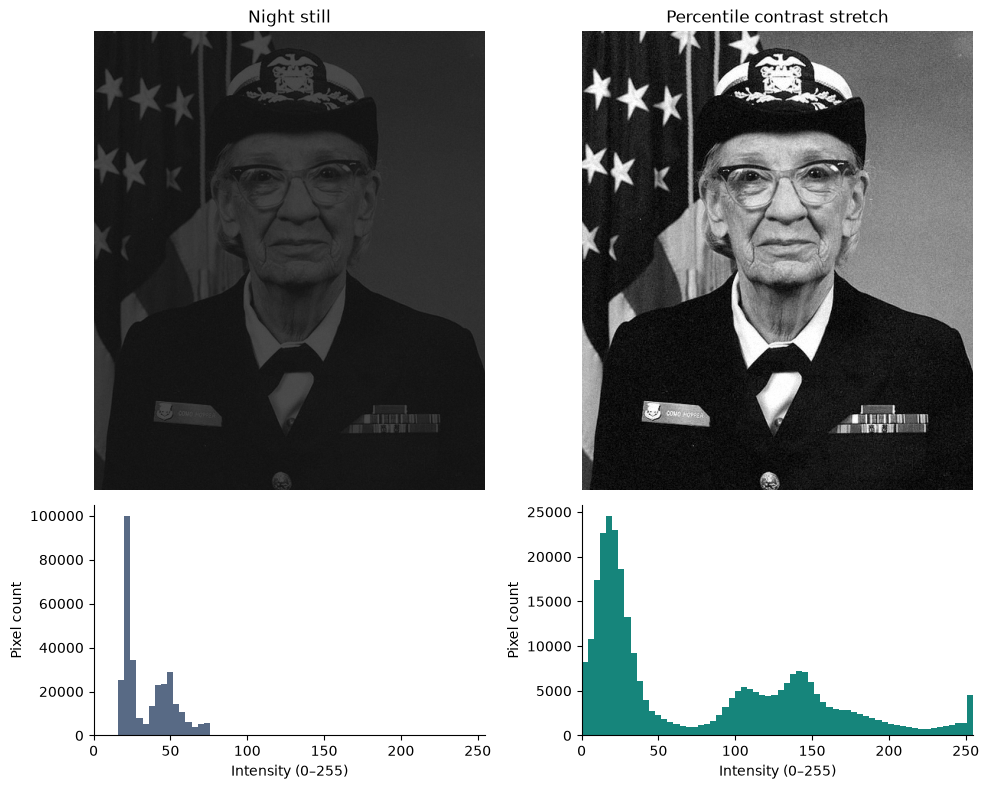

Original 1st–99th percentile range: 17.83–73.42
Contrast before: 0.609  ->  after: 1.000


In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

lmin, lmax = np.percentile(night_still, [1, 99])
c_before = michelson(lmax, lmin)
stretched = np.clip((night_still - lmin) * 255 / (lmax - lmin), 0, 255)
after_min, after_max = np.percentile(stretched, [1, 99])
c_after = michelson(after_max, after_min)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={'height_ratios': [2, 1]})
for col, (image, title) in enumerate([(night_still, 'Night still'), (stretched, 'Percentile contrast stretch')]):
    axes[0, col].imshow(image, cmap='gray', vmin=0, vmax=255)
    axes[0, col].set_title(title)
    axes[0, col].axis('off')
    axes[1, col].hist(image.ravel(), bins=64, range=(0, 255), color=['#586a85', '#16857b'][col])
    axes[1, col].set(xlim=(0, 255), xlabel='Intensity (0–255)', ylabel='Pixel count')
plt.tight_layout(); plt.show()
print(f'Original 1st–99th percentile range: {lmin:.2f}–{lmax:.2f}')
print(f'Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}')

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

The histogram has a large dark peak and smaller peaks within a narrow range toward the left-hand end: the still has low brightness and low contrast, rather than using the full 0–255 range. Stretching spreads the existing intensity differences over the display range, making edges and details easier to see without recovering any missing scene information. It also amplifies noise and clips the extreme 1% tails, so it is an aid to viewing rather than evidence enhancement that creates detail. A histogram counts intensities but discards their positions: rearranging every pixel would preserve the histogram while destroying the recognisable picture. The supplied still is a demonstration image, not an actual parking-lot evidence photograph.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Exact contiguous threshold ranges (tracking jitter fragments the standing state):
             State  First time (s)  Last time (s)
Standing (<3 px/s)         68.7000        68.7000
Standing (<3 px/s)         68.7667        68.7667
Standing (<3 px/s)         68.8667        70.5333
Standing (<3 px/s)         70.6000        70.8333
Standing (<3 px/s)         70.9000        71.1333
Standing (<3 px/s)         71.2000        71.6333
Standing (<3 px/s)         71.7000        72.0333
Standing (<3 px/s)         72.1000        72.1333
Standing (<3 px/s)         72.2333        72.7333
Standing (<3 px/s)         72.8000        73.2333
Standing (<3 px/s)         73.3000        73.7333
Standing (<3 px/s)         73.8000        73.9000
Standing (<3 px/s)         73.9667        74.0333
Standing (<3 px/s)         74.1000        74.2333
Standing (<3 px/s)         74.3000        74.6667
Standing (<3 px/s)         74.7333        75.3667
Standing (<3 px/s)         75.4333        75.4667
Standing (<3 px/s)

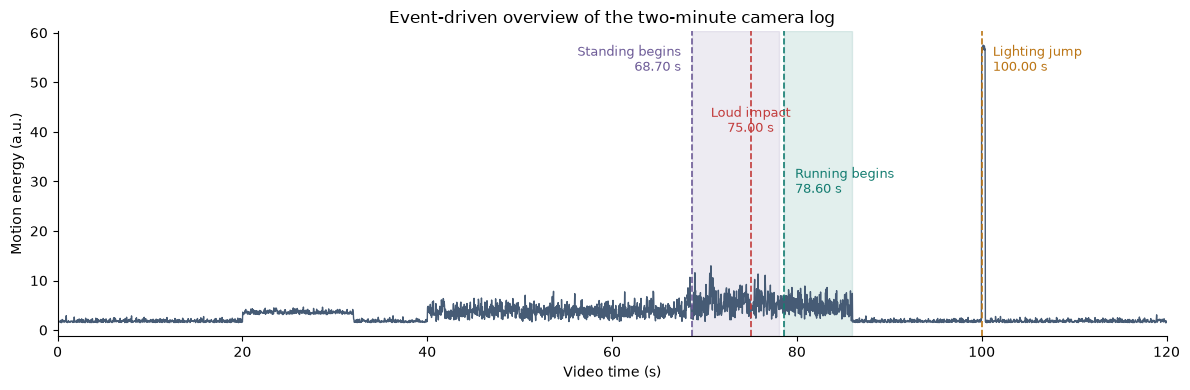

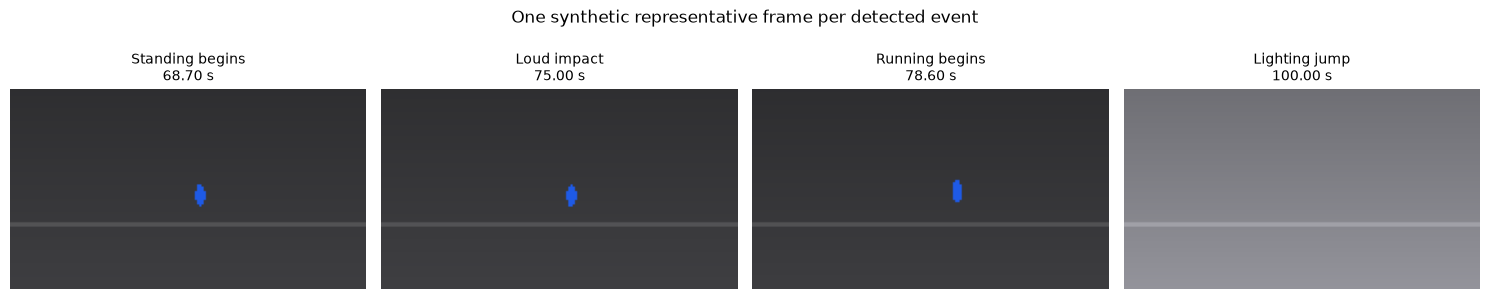

In [4]:
# FPS frames represent one second; the displacement is therefore in px/s.
# Missing positions stay missing and are never treated as zero speed.
speed = np.hypot(cctv.person_x.diff(FPS), cctv.person_y.diff(FPS))
standing = speed < 3
running = speed > 25

def contiguous_ranges(mask):
    indices = np.flatnonzero(np.asarray(mask, dtype=bool))
    if len(indices) == 0:
        return []
    groups = np.split(indices, np.flatnonzero(np.diff(indices) > 1) + 1)
    return [(int(g[0]), int(g[-1])) for g in groups]

exact_ranges = []
for label, mask in [('Standing (<3 px/s)', standing), ('Running (>25 px/s)', running)]:
    for start, end in contiguous_ranges(mask):
        exact_ranges.append({'State': label, 'First time (s)': cctv.time_s.iloc[start],
                             'Last time (s)': cctv.time_s.iloc[end]})
print('Exact contiguous threshold ranges (tracking jitter fragments the standing state):')
print(pd.DataFrame(exact_ranges).to_string(index=False, float_format=lambda v: f'{v:.4f}'))

# For the overview only, bridge gaps of at most 0.2 s inside the standing state.
# The exact threshold ranges above remain available for inspection.
standing_overview = ndimage.binary_closing(standing.to_numpy(), structure=np.ones(7))
standing_ranges = contiguous_ranges(standing_overview)
running_ranges = contiguous_ranges(running)
print('Overview standing intervals (gaps ≤0.2 s bridged):',
      [(float(cctv.time_s.iloc[a]), float(cctv.time_s.iloc[b])) for a, b in standing_ranges])

loud = cctv.audio_level_db > -20
audio_event_idx = np.flatnonzero((loud & ~loud.shift(fill_value=False)).to_numpy())
lighting_event_idx = np.flatnonzero((cctv.mean_brightness.diff() > 40).to_numpy())
events = [(a, 'Standing begins') for a, b in standing_ranges]
events += [(int(i), 'Loud impact') for i in audio_event_idx]
events += [(a, 'Running begins') for a, b in running_ranges]
events += [(int(i), 'Lighting jump') for i in lighting_event_idx]
events.sort()
event_colors = ['#6d5b97', '#c23b3b', '#147d71', '#bb7515']

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(cctv.time_s, cctv.motion_energy, color='#465b75', lw=1, label='Motion energy')
for (start, end) in standing_ranges:
    ax.axvspan(cctv.time_s.iloc[start], cctv.time_s.iloc[end], alpha=0.12, color='#6d5b97')
for (start, end) in running_ranges:
    ax.axvspan(cctv.time_s.iloc[start], cctv.time_s.iloc[end], alpha=0.12, color='#147d71')
for j, ((idx, label), color) in enumerate(zip(events, event_colors)):
    t_event = cctv.time_s.iloc[idx]
    ax.axvline(t_event, color=color, ls='--', lw=1.2)
    ax.annotate(f'{label}\n{t_event:.2f} s', xy=(t_event, [0.96, 0.76, 0.56, 0.96][j]), xycoords=('data', 'axes fraction'),
                xytext=([-8, 0, 8, 8][j], 0), textcoords='offset points',
                ha=['right', 'center', 'left', 'left'][j], va='top', fontsize=9, color=color)
ax.set(xlim=(0, 120), xlabel='Video time (s)', ylabel='Motion energy (a.u.)',
       title='Event-driven overview of the two-minute camera log')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(events), figsize=(15, 3.4), squeeze=False)
for ax, (idx, label) in zip(axes.flat, events):
    ax.imshow(render_frame(cctv.iloc[idx]))
    ax.set_title(f'{label}\n{cctv.time_s.iloc[idx]:.2f} s', fontsize=10)
    ax.axis('off')
fig.suptitle('One synthetic representative frame per detected event', y=0.98)
plt.tight_layout(); plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

Uniform frames at 0, 20, 40, 60, 80 and 100 s would miss the standing onset near 68.7 s and the impact at 75 s. The 80 s frame could show the person running, but would miss the transition at 78.6 s and the preceding context; the 100 s sample happens to catch the lighting jump. The impact is especially easy to miss because it is brief, and a still alone cannot record the sound. I used content-based keyframe selection (event-driven sampling): motion state transitions, an audio threshold crossing and a brightness jump choose the timestamps instead of a fixed sampling interval. The renderer provides schematic frames from the log, not recovered CCTV footage; temporal association alone does not establish who caused the impact.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

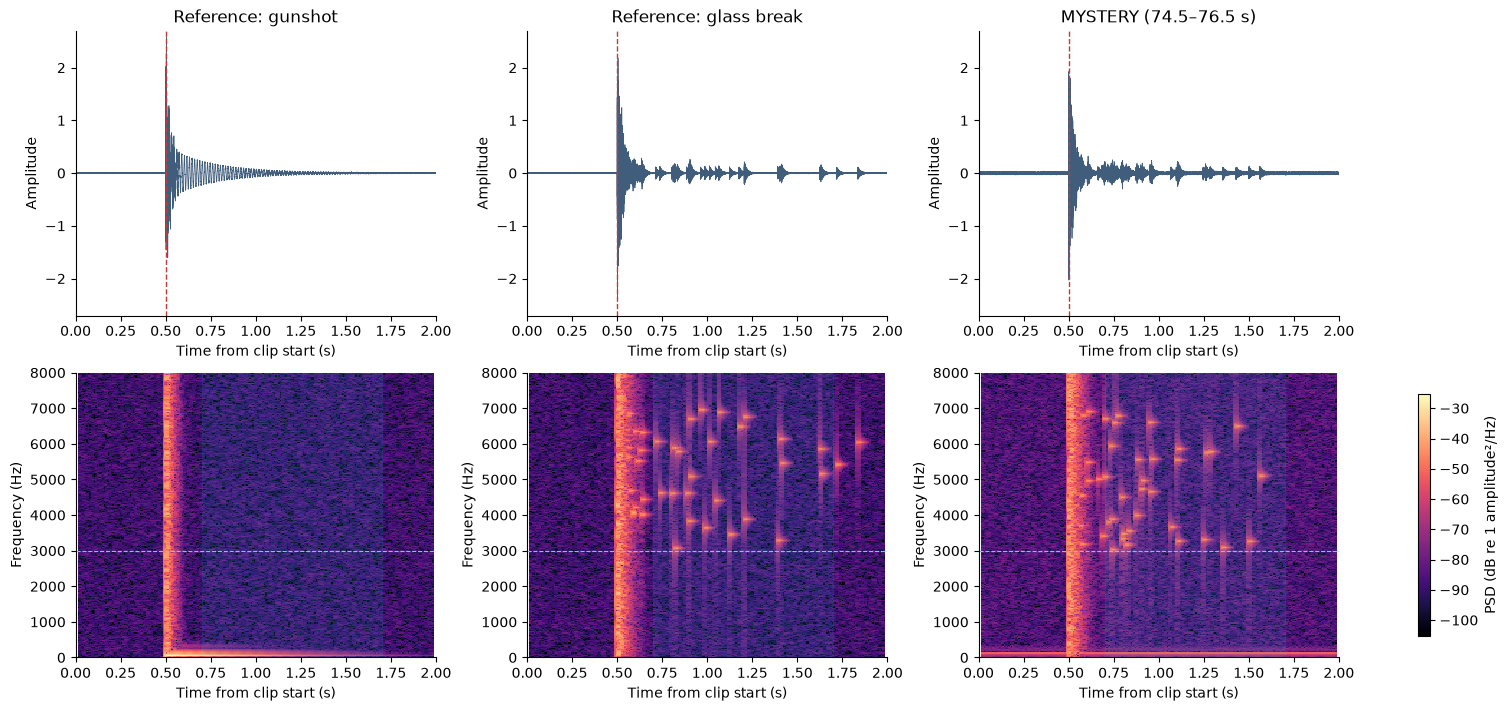

Reference: gunshot: energy above 3 kHz = 0.30%
Reference: glass break: energy above 3 kHz = 98.92%
MYSTERY (74.5–76.5 s): energy above 3 kHz = 87.35%
Verdict: the 75 s mystery impact is most consistent with a glass break; its tail contains lingering high-frequency specks matching the glass reference.


In [5]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {'Reference: gunshot': ref_gunshot[1], 'Reference: glass break': ref_glass[1],
         'MYSTERY (74.5–76.5 s)': mystery}
spectra = {}
for name, clip in clips.items():
    f, t, power = signal.spectrogram(clip, fs=FS, nperseg=512, noverlap=384)
    spectra[name] = (f, t, power)
# Use a common dB reference and color range for fair visual comparison.
max_db = max(10 * np.log10(np.maximum(p, 1e-15)).max() for f, t, p in spectra.values())
wave_limit = max(np.abs(clip).max() for clip in clips.values()) * 1.05
fig, axes = plt.subplots(2, 3, figsize=(15, 7), layout='constrained')
for col, (name, clip) in enumerate(clips.items()):
    local_t = np.arange(len(clip)) / FS
    axes[0, col].plot(local_t, clip, lw=0.55, color='#405d7c')
    axes[0, col].axvline(0.5, color='#c23b3b', ls='--', lw=1)
    axes[0, col].set(title=name, xlim=(0, 2), ylim=(-wave_limit, wave_limit),
                     xlabel='Time from clip start (s)', ylabel='Amplitude')
    f, t, power = spectra[name]
    mesh = axes[1, col].pcolormesh(t, f, 10 * np.log10(np.maximum(power, 1e-15)),
                                  shading='auto', cmap='magma', vmin=max_db - 80, vmax=max_db)
    axes[1, col].axvspan(0.7, 1.7, color='cyan', alpha=0.08)
    axes[1, col].axhline(3000, color='cyan', ls='--', lw=0.8)
    axes[1, col].set(xlim=(0, 2), ylim=(0, 8000), xlabel='Time from clip start (s)', ylabel='Frequency (Hz)')
fig.colorbar(mesh, ax=axes[1, :], label='PSD (dB re 1 amplitude²/Hz)', shrink=0.85)
plt.show()

# Impact occurs at local 0.5 s: evaluate the tail from 0.7 to 1.7 s.
# Equal time/frequency bin widths cancel in the energy ratio.
hf_fraction = {}
for name, (f, t, power) in spectra.items():
    tail = power[:, (t >= 0.7) & (t <= 1.7)]
    hf_fraction[name] = tail[f > 3000].sum() / tail.sum()
for name, fraction in hf_fraction.items():
    print(f'{name}: energy above 3 kHz = {fraction:.2%}')
mystery_name = list(clips)[-1]
nearest_reference = min(list(clips)[:2], key=lambda name: abs(hf_fraction[name] - hf_fraction[mystery_name]))
verdict = 'glass break' if nearest_reference == 'Reference: glass break' else 'gunshot'
print(f'Verdict: the 75 s mystery impact is most consistent with a {verdict}; '
      'its tail contains lingering high-frequency specks matching the glass reference.')

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

I could locate the sharp impact from the waveforms, but I would not confidently identify the source from amplitude against time alone: both references have a strong transient followed by a decay. A spectrogram adds time on the horizontal axis, frequency on the vertical axis and spectral magnitude (here power in dB) in color. The gunshot has a brief broadband vertical stripe and a low-frequency horizontal decay, while glass has scattered high-frequency specks after the initial impact. Those lingering specks in the mystery clip, supported by its greater fraction of tail energy above 3 kHz, decide the glass-break verdict. This is a comparison within the supplied synthetic examples, not a validated classifier for arbitrary field recordings.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

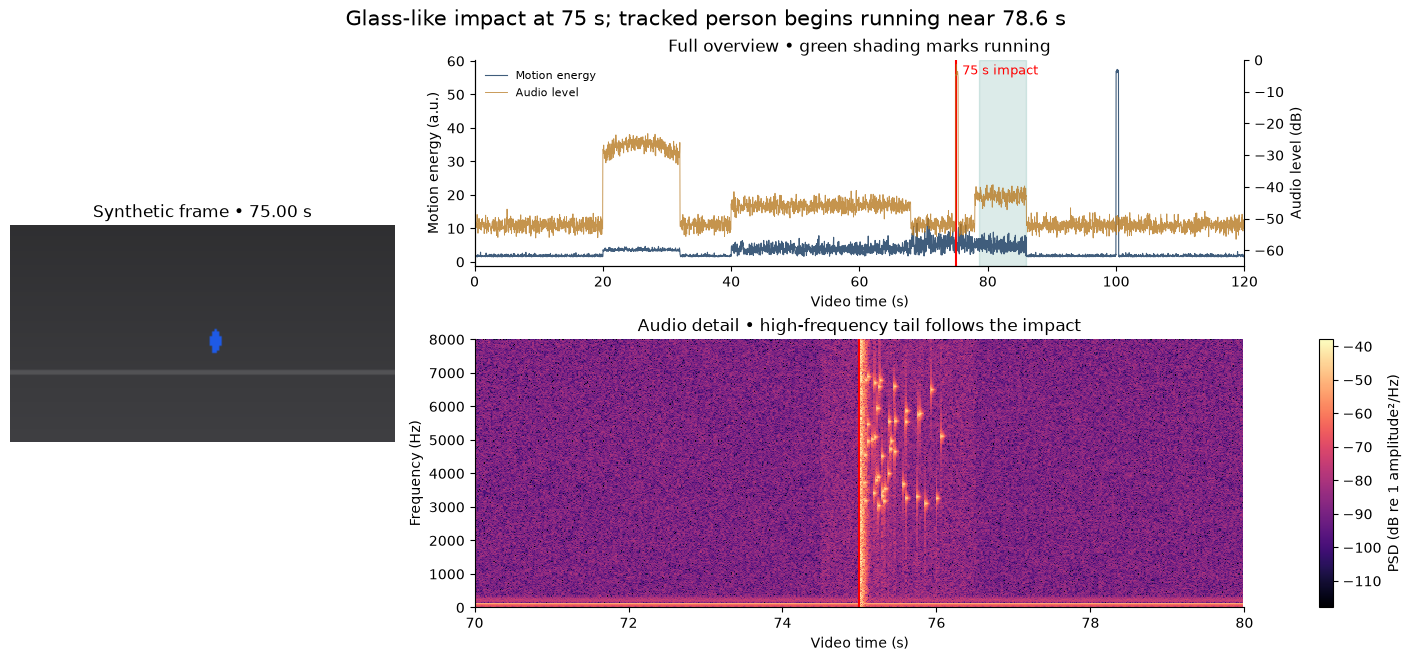

In [6]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6.5), layout='constrained')
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
ax_frame = fig.add_subplot(gs[:, 0])
selected_idx = int(np.argmin(np.abs(cctv.time_s.to_numpy() - t_sel)))
ax_frame.imshow(render_frame(cctv.iloc[selected_idx]))
ax_frame.set_title(f'Synthetic frame • {cctv.time_s.iloc[selected_idx]:.2f} s')
ax_frame.axis('off')

ax_timeline = fig.add_subplot(gs[0, 1])
motion_line, = ax_timeline.plot(cctv.time_s, cctv.motion_energy, color='#405d7c', lw=0.8, label='Motion energy')
ax_db = ax_timeline.twinx()
audio_line, = ax_db.plot(cctv.time_s, cctv.audio_level_db, color='#b77921', lw=0.65, alpha=0.8, label='Audio level')
ax_db.spines['right'].set_visible(True)
ax_db.set(ylabel='Audio level (dB)', ylim=(-65, 0))
for start, end in running_ranges:
    ax_timeline.axvspan(cctv.time_s.iloc[start], cctv.time_s.iloc[end], color='#147d71', alpha=0.15)
ax_timeline.axvline(t_sel, color='red', lw=1.5)
ax_timeline.text(t_sel + 1, 0.93, '75 s impact', transform=ax_timeline.get_xaxis_transform(), color='red', fontsize=9)
ax_timeline.set(xlim=(0, 120), xlabel='Video time (s)', ylabel='Motion energy (a.u.)',
                title='Full overview • green shading marks running')
ax_timeline.legend(handles=[motion_line, audio_line], loc='upper left', fontsize=8, frameon=False)

ax_spec = fig.add_subplot(gs[1, 1])
f, t, power = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
db = 10 * np.log10(np.maximum(power, 1e-15))
mesh = ax_spec.pcolormesh(70 + t, f, db, shading='auto', cmap='magma', vmin=db.max() - 80, vmax=db.max())
ax_spec.axvline(t_sel, color='red', lw=1.5)
ax_spec.set(xlim=(70, 80), ylim=(0, 8000), xlabel='Video time (s)', ylabel='Frequency (Hz)',
            title='Audio detail • high-frequency tail follows the impact')
fig.colorbar(mesh, ax=ax_spec, label='PSD (dB re 1 amplitude²/Hz)', pad=0.02)
fig.suptitle('Glass-like impact at 75 s; tracked person begins running near 78.6 s', fontsize=15)
plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

If a +2 s offset means that audio is displayed two seconds late, the real 75 s impact would appear at video time 77 s. The frame and its red marker would then be paired with the wrong audio moment, potentially suggesting that a different movement caused the sound. The bottom-right spectrogram would reveal the error because the broadband onset would fall at 77 s rather than on the shared 75 s marker; comparison with the log’s audio spike in the overview provides another check. Keeping both panels in the video’s absolute seconds, and labeling the selected time once consistently, helps reveal a synchronization error without adding more panels.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

The supplied Lot B log shows a standing period around 68.7–78.1 s (with brief tracking-jitter gaps), a glass-like impact at 75 s, running from about 78.6–86.0 s, and a lighting jump at 100 s; it does not establish who caused the impact. I would put the synchronized view first because its overview timeline directs attention to the event and its shared timestamp links the schematic keyframe to the audio detail. The spectrogram’s time × frequency × magnitude view shows the lingering high-frequency tail that makes the sound more consistent with the glass-break reference than the gunshot reference. Raw 1080p/30 fps recording for 400 cameras needs about 5,866.0 binary TB per day, while 360p/10 fps needs about 217.3, a 27-fold reduction. I recommend a lower-resolution continuous overview with compressed full-resolution/30 fps event clips, retaining a rolling pre-event buffer and synchronized audio, with capacity measured from actual encoded bitrates and retention rather than these raw totals. That policy must preserve full-resolution licence-plate detail around incidents, since spatial information discarded by downsampling cannot be restored later.